# Predicting Weekly Work Hours
## ANA500 Micro-Project 3
Douglas Bobeck | October 4, 2026

This project uses linear regression, support vector regression, and decision tree
regression to predict weekly work hours. It covers **Acquire, Prepare, Analyze,
Report, and Act**. The work uses Jupyter Notebook, Python, Pandas, NumPy,
Matplotlib, and scikit-learn.

## Summary
Support vector regression had the lowest cross-validation RMSE and also the
lowest test errors among the three models. On 6,513 held-out records, its MAE
was **7.16 hours**, RMSE was **10.89 hours**, and R-squared was **0.225**.
Its test RMSE was **12.0% below the mean baseline**. The decision tree was close
at 10.96 hours RMSE; this small difference is not proof of superiority.

The model was much less accurate for short and long workweeks. It is useful for
this classroom comparison, but it is not a reliable basis for individual
scheduling or employment decisions.

## Problem statement and hypothesis
**Problem:** Adults work different numbers of hours each week. How accurately can
age, education, occupation, and workclass predict weekly work hours in the Adult
dataset?

**Hypothesis:** These characteristics together will predict weekly work hours
more accurately than a model that always predicts the training sample's average
hours. Job roles and employment arrangements may help explain the differences.
Lower cross-validation RMSE is the model-selection criterion. Performance on
separate test records will show whether the improvement carries over.

### Why the outcome changed
Module 2 examined income categories. Module 3 asks for regression, but Adult
does not provide actual salary amounts. This module therefore predicts
`hours-per-week`, an observed numerical value. Income classification remains a
separate question for later work. Weeks 1 and 2 are unchanged.

### Method and assumptions
- Retain original age and work-hour values. Grouped hours are used only for
  error summaries, never as predictors. Education is categorical; its numerical
  code is not interpreted as years of schooling.
- Use the same four predictors and the same split for all three models.
- Keep about 20% of records as a final test set. Keep identical full profiles
  together across the split and within training cross-validation.
- Select settings and a preferred model with three-fold cross-validation on
  training records only. Learn scaling and category encoding within each fold.
- Use RMSE to select the model; also report MAE and R-squared. The baseline
  always predicts the mean of the training records available to it.
- Treat each record equally. Keep `fnlwgt` but do not use it as a predictor or
  weight. Results concern this historical sample, not the current population.
- A better prediction does not establish a causal effect or prove why hours differ.

## 1. Acquire
The input is the same supplied Adult CSV used in earlier modules: 32,561 records
and 15 fields, from the 1994 Census database. It matches UCI's training sample.
The separate UCI test file is not used; this project creates its own held-out
test set within the supplied file. Earlier exploratory work viewed this sample,
so this is an internal validation exercise, not independent external validation.

The unchanged input is included as `adult_income.csv` beside this notebook.
Source: Becker, B., & Kohavi, R. (1996). *Adult* [Dataset].
[UCI Machine Learning Repository](https://doi.org/10.24432/C5XW20), CC BY 4.0.

In [1]:
# Import the tools for preparation, modeling, evaluation, and charts.
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
%matplotlib inline

# Open the notebook from its folder, or from the repository's parent directory.
week_dir = Path.cwd()
if (week_dir / "week3" / "Micro_Project_3.ipynb").is_file():
    week_dir = week_dir / "week3"
data_file = week_dir / "adult_income.csv"
if not data_file.is_file():
    raise FileNotFoundError("Open the notebook beside adult_income.csv.")
source_hash = hashlib.sha256(data_file.read_bytes()).hexdigest()
assert source_hash == "f2c62076f19504d99a38b22badf445a7f42530ade6b827acf78dd143fbce38bb"
raw = pd.read_csv(data_file, dtype="string", keep_default_na=False)
output_dir = week_dir / "outputs"
output_dir.mkdir(exist_ok=True)
SEED = 42
versions = {"Python": platform.python_version(), "Pandas": pd.__version__,
            "NumPy": np.__version__, "Matplotlib": matplotlib.__version__,
            "scikit-learn": sklearn.__version__}
print(f"Input: {len(raw):,} rows and {len(raw.columns)} columns")
print("Tools:", versions)
display(raw[["age", "education", "occupation", "workclass", "hours-per-week"]].head(3))

Input: 32,561 rows and 15 columns
Tools: {'Python': '3.11.5', 'Pandas': '2.2.2', 'NumPy': '1.26.4', 'Matplotlib': '3.8.4', 'scikit-learn': '1.4.2'}


,age,education,occupation,workclass,hours-per-week
0,39,Bachelors,Adm-clerical,State-gov,40
1,50,Bachelors,Exec-managerial,Self-emp-not-inc,13
2,38,HS-grad,Handlers-cleaners,Private,40


## 2. Prepare
Trim spaces, mark missing entries, validate numerical values, and check education
codes. Keep all records, including valid extreme hours and the 24 repeated full
profiles beyond the first occurrence. Without person identifiers, matching
profiles are not proof that the records are erroneous duplicates.

Missing occupation and workclass are represented as **Unknown**. This fixed label
does not learn information from test records. No outcome is filled in or clipped.

In [2]:
# Check the expected fields before changing any values.
columns = ("age workclass fnlwgt education education-num marital-status occupation "
           "relationship race sex capital-gain capital-loss hours-per-week "
           "native-country income").split()
assert list(raw.columns) == columns and raw.shape == (32561, 15)
data = raw.copy(deep=True)
for column in columns:
    data[column] = data[column].str.strip().replace({"?": pd.NA, "": pd.NA})
missing = data.isna().sum()
assert data[["age", "education", "education-num", "sex", "hours-per-week", "income"]].notna().all().all()
assert data["income"].isin(["<=50K", ">50K"]).all()
assert data["sex"].isin(["Female", "Male"]).all()

# Reject invalid numbers rather than silently changing them.
numeric = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
for column in numeric:
    values = pd.to_numeric(data[column], errors="raise")
    assert np.isfinite(values).all() and (values % 1 == 0).all()
    data[column] = values.astype("int64")
values = data[numeric].to_numpy()
assert ((values >= [17, 1, 1, 0, 0, 1]) &
        (values <= [120, np.inf, 16, np.inf, np.inf, 168])).all()
education_codes = dict(zip([
    "Preschool", "1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th",
    "HS-grad", "Some-college", "Assoc-voc", "Assoc-acdm", "Bachelors", "Masters",
    "Prof-school", "Doctorate"], range(1, 17)))
assert data["education"].map(education_codes).eq(data["education-num"]).all()

# Keep repeated profiles and valid extremes; matching values do not identify a person.
repeat_count = int(data.duplicated().sum())
missing_rows = int(data.isna().any(axis=1).sum())
assert repeat_count == 24 and missing_rows == 2399
display(missing[missing > 0].rename("Missing records").to_frame())
print(f"Rows retained: {len(data):,}; repeated profiles beyond the first: {repeat_count}")

,Missing records
workclass,1836
occupation,1843
native-country,583


Rows retained: 32,561; repeated profiles beyond the first: 24


### Predictors and data split
Use original age and three categorical fields: education, occupation, and
workclass. Exclude income, survey weight, duplicate education codes, and all
hour-derived fields from the predictors. This keeps the question focused and
prevents the outcome from leaking into the inputs.

The 80/20 split is made by full-profile groups, so its row counts may differ
slightly from an exact 80/20 row split. Identical profiles remain together.

In [3]:
# Select only the four agreed predictors and the original numerical outcome.
features = ["age", "education", "occupation", "workclass"]
categories = ["education", "occupation", "workclass"]
X = data[features].copy()
X[categories] = X[categories].fillna("Unknown").astype(str)
y = data["hours-per-week"].astype(float)

# Full-profile groups prevent exact repeated records from crossing partitions.
profile_groups = data.groupby(list(data.columns), dropna=False, sort=False).ngroup()
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups=profile_groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_groups = profile_groups.iloc[train_idx]
assert not set(train_groups) & set(profile_groups.iloc[test_idx])
assert len(train_idx) + len(test_idx) == len(data)

# Materialize the same three training folds for every candidate model.
folds = list(GroupKFold(n_splits=3).split(X_train, y_train, train_groups))
for fit_idx, valid_idx in folds:
    assert not set(train_groups.iloc[fit_idx]) & set(train_groups.iloc[valid_idx])
print(f"Training records: {len(train_idx):,}; test records: {len(test_idx):,}")
print(f"Training mean: {y_train.mean():.2f} hours; median: {y_train.median():.0f}")
print(f"Training records at exactly 40 hours: {100*y_train.eq(40).mean():.1f}%")
display(y_train.describe().round(2).to_frame("Training hours"))

Training records: 26,048; test records: 6,513
Training mean: 40.39 hours; median: 40
Training records at exactly 40 hours: 46.8%


,Training hours
count,26048.00
mean,40.39
std,12.34
min,1.00
25%,40.00
50%,40.00
75%,45.00
max,99.00


### Distribution of the outcome
Inspect training hours before modeling. A concentration near 40 hours and a long
range can make unusual workweeks harder to predict. The test outcomes are not
used to choose features, settings, or the preferred model.

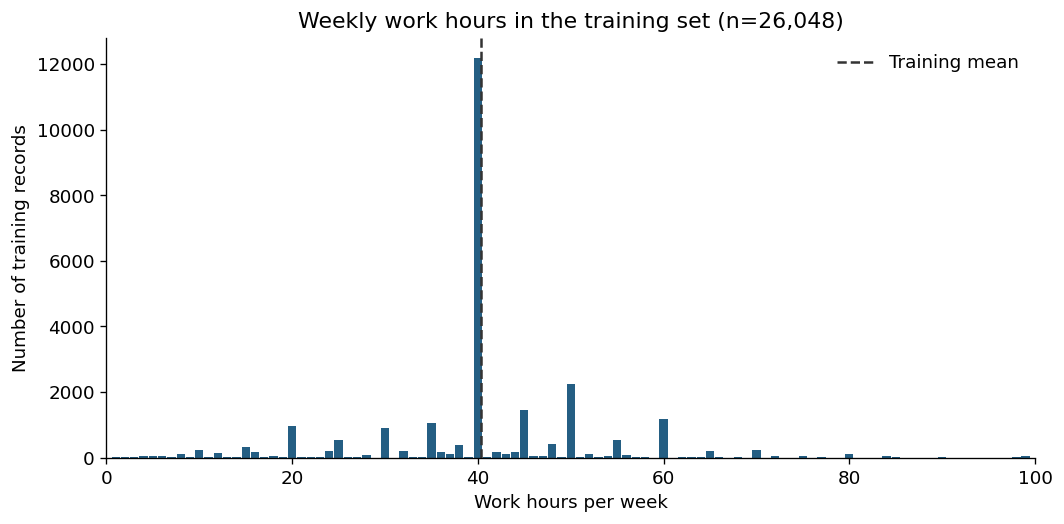

In [4]:
# Use a consistent chart style and label the population and units.
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})
colors = {"Mean baseline": "#767676", "Linear regression": "#245E83",
          "Support vector regression": "#AA6520", "Decision tree regression": "#647744"}
fig, ax = plt.subplots(figsize=(9, 4.5))
hour_counts = y_train.value_counts().sort_index()
ax.bar(hour_counts.index, hour_counts.values, width=0.9, color="#245E83")
ax.set(xlabel="Work hours per week", ylabel="Number of training records",
       title=f"Weekly work hours in the training set (n={len(y_train):,})", xlim=(0, 100))
ax.axvline(y_train.mean(), color="#333333", linestyle="--", label="Training mean")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(output_dir / "01_training_hours.png", dpi=160)
plt.show()

## 3. Analyze
### Three regression models and a baseline
**Linear regression** is the simplest relationship model. **Support vector
regression** uses an RBF kernel to allow nonlinear relationships. **Decision tree
regression** learns branching rules and combinations of predictors.

All models see the same information. Category encoding uses training data only
and tolerates categories not seen during fitting. Scaling age supports SVR and
also keeps one shared preparation pipeline for the comparison. The tree is
unaffected by this monotonic scaling. A dropped reference category avoids
redundant columns in linear regression.

The SVR search tests C = 1 or 10 and epsilon = 0.5 or 2 hours. The tree search
tests depths 3, 5, or 8 and minimum leaf sizes 25 or 100. These are small,
predefined searches, not an exhaustive search for every possible model.

In [5]:
# Each pipeline learns its transformations separately inside each training fold.
prepare = ColumnTransformer([
    ("age", StandardScaler(), ["age"]),
    ("categories", OneHotEncoder(drop="first", handle_unknown="ignore",
                                  sparse_output=False), categories)
])
models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Support vector regression": SVR(kernel="rbf", cache_size=512),
    "Decision tree regression": DecisionTreeRegressor(random_state=SEED)
}
grids = {
    "Mean baseline": {},
    "Linear regression": {},
    "Support vector regression": {"model__C": [1.0, 10.0],
                                  "model__epsilon": [0.5, 2.0]},
    "Decision tree regression": {"model__max_depth": [3, 5, 8],
                                   "model__min_samples_leaf": [25, 100]}
}
print("Selection criterion: lowest mean validation RMSE across the same three folds.")

Selection criterion: lowest mean validation RMSE across the same three folds.


### Select settings with training records
RMSE is the square root of mean squared prediction error. It is in hours and
penalizes large misses more strongly than MAE. The fold standard deviation below
describes variation between three folds; it is not a confidence interval.

The test set remains unused during this step. The preferred regression model
is selected here and will not be changed after viewing test scores.

In [6]:
# Fit every candidate on the same folds; refit the best settings on all training rows.
searches, cv_rows = {}, []
for name, estimator in models.items():
    pipeline = Pipeline([("prepare", clone(prepare)), ("model", estimator)])
    search = GridSearchCV(pipeline, grids[name], cv=folds,
                          scoring="neg_root_mean_squared_error", n_jobs=1,
                          refit=True, error_score="raise")
    search.fit(X_train, y_train)
    assert np.isfinite(search.cv_results_["mean_test_score"]).all()
    searches[name] = search
    best = search.best_index_
    cv_rows.append({"Model": name, "CV RMSE": -search.best_score_,
                    "Fold SD": search.cv_results_["std_test_score"][best],
                    "Settings": str(search.best_params_)})
    print(f"Finished: {name}")
cv_table = pd.DataFrame(cv_rows).set_index("Model")
selected = cv_table.drop(index="Mean baseline")["CV RMSE"].idxmin()
display(cv_table.drop(columns="Settings").round(3))
for name, search in searches.items():
    if search.best_params_:
        print(name, search.best_params_)
print("Preferred regression model selected before test evaluation:", selected)

Finished: Mean baseline
Finished: Linear regression


Finished: Support vector regression


Finished: Decision tree regression


,CV RMSE,Fold SD
Model,,
Mean baseline,12.340,0.240
Linear regression,11.542,0.199
Support vector regression,10.926,0.187
Decision tree regression,11.021,0.167


Support vector regression {'model__C': 10.0, 'model__epsilon': 2.0}
Decision tree regression {'model__max_depth': 8, 'model__min_samples_leaf': 25}
Preferred regression model selected before test evaluation: Support vector regression


### Final test comparison
Evaluate the frozen models on the same held-out records. **MAE** is the average
absolute miss in hours. **R-squared** compares squared error with predicting the
test outcome's mean; it can be negative. The explicit mean baseline instead
uses the training mean, so its test R-squared need not be exactly zero.

These are point estimates from one internal test set. Small differences should
not be described as statistically proven superiority.

In [7]:
# Predict once on the test set; do not use these results to retune the models.
predictions, test_rows = {}, []
for name, search in searches.items():
    pred = search.predict(X_test)
    predictions[name] = pred
    test_rows.append({"Model": name,
                      "MAE": mean_absolute_error(y_test, pred),
                      "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                      "R-squared": r2_score(y_test, pred)})
test_table = pd.DataFrame(test_rows).set_index("Model")
comparison = cv_table[["CV RMSE", "Fold SD"]].join(test_table)
display(comparison.round(3))
baseline_rmse = test_table.loc["Mean baseline", "RMSE"]
chosen_rmse = test_table.loc[selected, "RMSE"]
improvement = 100 * (baseline_rmse - chosen_rmse) / baseline_rmse
print(f"Selected model: {selected}; test RMSE improvement over baseline: {improvement:.1f}%")

,CV RMSE,Fold SD,MAE,RMSE,R-squared
Model,,,,,
Mean baseline,12.340,0.240,7.607,12.371,-0.000
Linear regression,11.542,0.199,7.873,11.565,0.126
Support vector regression,10.926,0.187,7.164,10.889,0.225
Decision tree regression,11.021,0.167,7.494,10.964,0.214


Selected model: Support vector regression; test RMSE improvement over baseline: 12.0%


### Compare errors visually
Lower errors are better. Cross-validation selected the preferred model; the test
comparison checks whether that result carries over. Different metrics can favor
different models, so the primary metric was chosen before fitting.

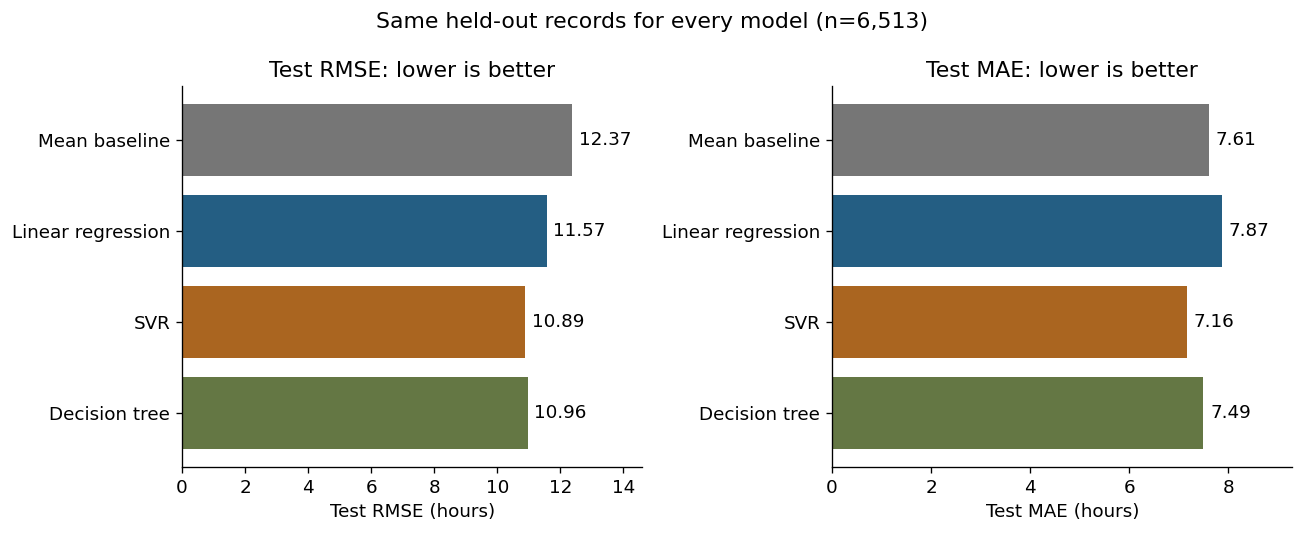

In [8]:
# Show all models in the same order, with common axes and direct value labels.
names = list(models)
short_names = ["Mean baseline", "Linear regression", "SVR", "Decision tree"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, metric in zip(axes, ["RMSE", "MAE"]):
    vals = test_table.loc[names, metric].to_numpy()
    bars = ax.barh(short_names, vals, color=[colors[n] for n in names])
    ax.bar_label(bars, fmt="%.2f", padding=4)
    ax.invert_yaxis()
    ax.set(xlabel=f"Test {metric} (hours)", xlim=(0, max(vals)*1.18),
           title=f"Test {metric}: lower is better")
fig.suptitle(f"Same held-out records for every model (n={len(y_test):,})")
fig.tight_layout()
fig.savefig(output_dir / "02_model_errors.png", dpi=160)
plt.show()

### Inspect the selected model's predictions
The scatterplot uses a fixed random sample of up to 500 test records so points
remain readable. The residual histogram uses every test record. Residual means
actual hours minus predicted hours; positive values indicate underprediction.

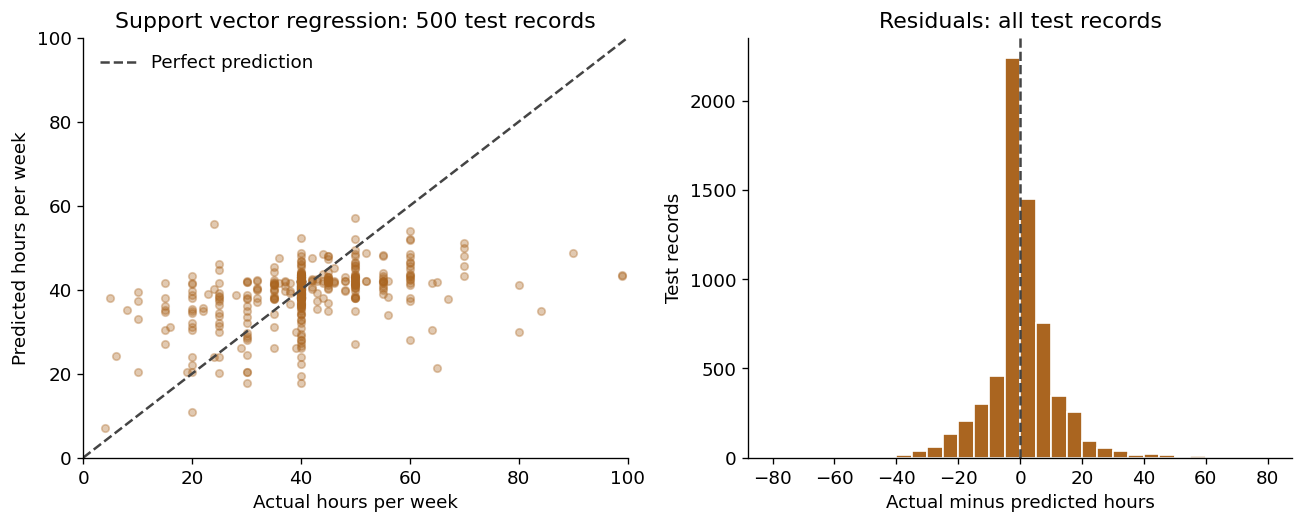

In [9]:
# Inspect errors without changing the selected model or its settings.
chosen_predictions = predictions[selected]
residuals = y_test.to_numpy() - chosen_predictions
plot_idx = np.random.default_rng(SEED).choice(len(y_test),
                                            size=min(500, len(y_test)), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(y_test.iloc[plot_idx], chosen_predictions[plot_idx],
                alpha=0.35, s=20, color=colors[selected])
axes[0].plot([0, 100], [0, 100], "--", color="#444444", label="Perfect prediction")
axes[0].set(xlabel="Actual hours per week", ylabel="Predicted hours per week",
            title=f"{selected}: 500 test records", xlim=(0, 100), ylim=(0, 100))
axes[0].legend(frameon=False)
residual_counts, residual_edges, _ = axes[1].hist(
    residuals, bins=np.arange(-80, 85, 5), color=colors[selected], edgecolor="white")
axes[1].axvline(0, linestyle="--", color="#444444")
axes[1].set(xlabel="Actual minus predicted hours", ylabel="Test records",
            title="Residuals: all test records")
fig.tight_layout()
fig.savefig(output_dir / "03_prediction_diagnostics.png", dpi=160)
plt.show()

### Where the model misses
Summarize errors by actual work-hour bands after prediction. These bands are
diagnostics, not model inputs. The table shows whether an overall average error
hides larger errors for shorter or longer workweeks.

,n,actual_mean,predicted_mean,MAE,mean_residual
hours_band,,,,,
Under 35,1124,21.61,34.86,13.81,-13.25
35-40,3418,39.54,40.26,2.75,-0.73
Over 40,1971,53.34,42.61,11.02,10.73


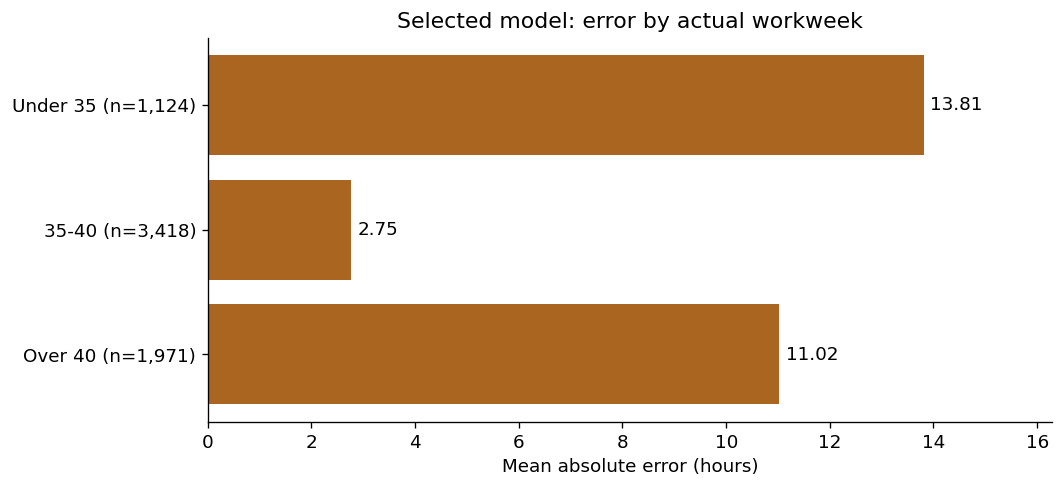

In [10]:
# Retain actual values and add separate diagnostic labels.
test_details = pd.DataFrame({"source_row": test_idx + 1,
                            "actual_hours": y_test.to_numpy(),
                            "predicted_hours": chosen_predictions})
test_details["hours_band"] = pd.cut(test_details["actual_hours"],
                                   [0, 34, 40, 100], labels=["Under 35", "35-40", "Over 40"])
test_details["absolute_error"] = np.abs(residuals)
test_details["residual"] = residuals
error_groups = test_details.groupby("hours_band", observed=False).agg(
    n=("actual_hours", "size"), actual_mean=("actual_hours", "mean"),
    predicted_mean=("predicted_hours", "mean"),
    MAE=("absolute_error", "mean"), mean_residual=("residual", "mean"))
display(error_groups.round(2))
fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.barh([f"{band} (n={row.n:,.0f})" for band, row in error_groups.iterrows()],
               error_groups["MAE"], color=colors[selected])
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.invert_yaxis()
ax.set(xlabel="Mean absolute error (hours)", title="Selected model: error by actual workweek",
       xlim=(0, error_groups["MAE"].max()*1.18))
fig.tight_layout()
fig.savefig(output_dir / "04_errors_by_hours.png", dpi=160)
plt.show()

### Checks
Recalculate the reported scores directly from the errors, reconcile group
counts, and verify that the original values and input file were preserved.
These checks can be rerun with the notebook.

In [11]:
# Independent formulas check the library metrics for every model.
actual = y_test.to_numpy()
for name, pred in predictions.items():
    assert len(pred) == len(actual) and np.isfinite(pred).all()
    errors = actual - pred
    manual = [np.abs(errors).mean(), np.sqrt(np.square(errors).mean()),
              1 - np.square(errors).sum()/np.square(actual-actual.mean()).sum()]
    np.testing.assert_allclose(manual, test_table.loc[name, ["MAE", "RMSE", "R-squared"]])
np.testing.assert_allclose(predictions["Mean baseline"], y_train.mean())
assert int(residual_counts.sum()) == len(y_test)
assert error_groups["n"].sum() == len(y_test)
np.testing.assert_allclose(np.average(error_groups["MAE"], weights=error_groups["n"]),
                           test_table.loc[selected, "MAE"])
assert set(features) == {"age", "education", "occupation", "workclass"}
np.testing.assert_array_equal(data["hours-per-week"], raw["hours-per-week"].astype(int))
np.testing.assert_array_equal(data["age"], raw["age"].astype(int))
assert hashlib.sha256(data_file.read_bytes()).hexdigest() == source_hash
assert selected == cv_table.drop(index="Mean baseline")["CV RMSE"].idxmin()
print("PASS: split groups, metrics, baseline, group totals, original values, and input file.")
print("Predictions outside 1-99 hours:",
      {name: int(((pred < 1) | (pred > 99)).sum()) for name, pred in predictions.items()})

PASS: split groups, metrics, baseline, group totals, original values, and input file.
Predictions outside 1-99 hours: {'Mean baseline': 0, 'Linear regression': 0, 'Support vector regression': 0, 'Decision tree regression': 0}


## 4. Report
The following findings are calculated from the executed models. The outcome is
weekly hours, not income. The hypothesis concerns predictive usefulness; the
suggested explanation about job roles has not been established as a cause.

In [12]:
# Report the model chosen by cross-validation and its unchanged test results.
chosen = test_table.loc[selected]
report = (
    f"### Findings\n"
    f"- Cross-validation selected **{selected}** with RMSE "
    f"{cv_table.loc[selected, 'CV RMSE']:.2f} hours.\n"
    f"- On {len(y_test):,} test records, MAE is **{chosen['MAE']:.2f} hours**, "
    f"RMSE is **{chosen['RMSE']:.2f} hours**, and R-squared is **{chosen['R-squared']:.3f}**.\n"
    f"- Test RMSE is {improvement:.1f}% lower than the training-mean baseline "
    f"({baseline_rmse:.2f} hours).\n"
    f"- The largest band-specific MAE is for **{error_groups['MAE'].idxmax()}** "
    f"hours: {error_groups['MAE'].max():.2f} hours.\n"
    f"- These results {'support' if improvement > 0 else 'do not support'} the "
    f"predictive hypothesis on this internal test set. They do not establish causation."
)
display(Markdown(report))

### Findings
- Cross-validation selected **Support vector regression** with RMSE 10.93 hours.
- On 6,513 test records, MAE is **7.16 hours**, RMSE is **10.89 hours**, and R-squared is **0.225**.
- Test RMSE is 12.0% lower than the training-mean baseline (12.37 hours).
- The largest band-specific MAE is for **Under 35** hours: 13.81 hours.
- These results support the predictive hypothesis on this internal test set. They do not establish causation.

### Limitations
- This is a historical, unweighted sample. `fnlwgt` remains available, but
  population estimates would need a separate weighting analysis.
- Four predictors cannot capture all reasons for weekly hours. We do not observe
  every person's preferences, employer scheduling needs, or other commitments.
- The original file has no person or household ID. Keeping exact profiles
  together reduces one leakage risk but cannot rule out other dependencies.
- We used one internal test split and a small settings search. Test differences
  are not formal significance tests or proof of performance on today's workers.
- The earlier modules explored this same dataset. A new external dataset is
  needed before treating this as evidence of practical generalization.

## 5. Act
Apply the selected model to held-out records and compare the predictions with
their actual hours. The table below shows five test records, selected by source
row order rather than by the size of their errors. These are examples from the
historical dataset, not invented people or new predictions about current workers.

In [13]:
# Apply the selected fitted model to five held-out records for a readable example.
examples = test_details.sort_values("source_row").head(5).copy()
example_features = X.iloc[examples["source_row"].to_numpy()-1].reset_index(drop=True)
example_table = pd.concat([example_features,
                          examples[["actual_hours", "predicted_hours"]].reset_index(drop=True)], axis=1)
display(example_table.round(2))

# Save the measured results once so the presentation uses the same numbers.
summary = {
    "source_sha256": source_hash, "versions": versions, "seed": SEED,
    "rows": len(data), "train_rows": len(y_train), "test_rows": len(y_test),
    "training_mean": float(y_train.mean()), "training_median": float(y_train.median()),
    "training_40_percent": float(100*y_train.eq(40).mean()),
    "missing": {k: int(v) for k,v in missing[missing > 0].items()},
    "repeated_profiles": int(repeat_count), "features": features,
    "selected_model": selected, "test_rmse_improvement_percent": float(improvement),
    "comparison": comparison.reset_index().to_dict("records"),
    "settings": {name: search.best_params_ for name,search in searches.items()},
    "error_groups": error_groups.reset_index().to_dict("records"),
    "examples": example_table.to_dict("records"),
    "training_hour_counts": {str(int(k)): int(v) for k,v in hour_counts.items()},
    "scatter_actual": y_test.iloc[plot_idx].tolist(),
    "scatter_predicted": chosen_predictions[plot_idx].tolist(),
    "residual_counts": residual_counts.astype(int).tolist(),
    "residual_edges": residual_edges.tolist()
}
(output_dir / "analysis_summary.json").write_text(json.dumps(summary, indent=2, allow_nan=False))
comparison.to_csv(output_dir / "model_comparison.csv")
test_details.to_csv(output_dir / "test_predictions.csv", index=False)
print("Saved figures, comparison scores, selected-model predictions, and summary in outputs.")

,age,education,occupation,workclass,actual_hours,predicted_hours
0,49,9th,Other-service,Private,16.0,38.30
1,31,Masters,Prof-specialty,Private,50.0,42.27
2,23,Assoc-acdm,Protective-serv,Local-gov,52.0,40.43
3,30,Some-college,Adm-clerical,Federal-gov,40.0,41.35
4,22,Some-college,Other-service,State-gov,15.0,26.06


Saved figures, comparison scores, selected-model predictions, and summary in outputs.


### Decision
Keep support vector regression as the preferred model for this comparison,
based on its training-validation result. Its test performance supports the
hypothesis of improvement over the mean baseline, but only modestly: most
variation in hours remains unexplained. The decision tree is a close alternative;
one split does not establish a dependable advantage for SVR.

The selected model tends to overpredict short workweeks and underpredict long
ones. Average absolute errors are 13.81 hours for workweeks under 35 hours and
11.02 hours for workweeks over 40 hours. These errors limit individual use.

Use the findings to guide further study, rather than assign work schedules.
Before practical use, define an acceptable error, obtain current independent
data, and assess errors across relevant groups. Investigate survey weighting if
making population-level statements. Income classification can remain a separate
later project. This completes Step 5, Act.

## References
- Becker, B., & Kohavi, R. (1996). *Adult* [Dataset].
  [UCI Machine Learning Repository](https://doi.org/10.24432/C5XW20).
- scikit-learn documentation: [Linear regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html),
  [Support vector regression](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html),
  [Decision trees](https://scikit-learn.org/stable/modules/tree.html).
- scikit-learn documentation: [Avoiding data leakage](https://scikit-learn.org/stable/common_pitfalls.html).